# Estimate a discrete generalized equivalent layer

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
from scipy.fft import fftfreq, fftshift

In [5]:
import time

In [6]:
import pickle

In [7]:
from gravmag import data_structures, utils, aux_vedo, transforms, inverse_distance, convolve, filters, constants, eqlayer
from gravmag.models import rectangular_prism as rp

In [8]:
import vedo

In [9]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Set path for saving figures

In [10]:
figures = '../manuscript/figures/'

### Load data

In [11]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [12]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [13]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [14]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [15]:
mag_intensity = pickle.load(open('model/1_model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/1_model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/1_model_mag_dec.pickle', 'rb'))

In [16]:
main_field = pickle.load(open('model/2_main_field.pickle', 'rb'))

In [17]:
print('Main field inc = {}° dec = {}°'.format(main_field['inc'], main_field['dec']))

Main field inc = -30° dec = 10°


In [18]:
simulated_fields = pickle.load(open('model/2_simulated_fields.pickle', 'rb'))

In [19]:
coordinates_grid = pickle.load(open('model/2_coordinates_grid.pickle', 'rb'))

In [20]:
print('Regular grid of coordinates on the horizontal plane {} m'.format(coordinates_grid['z']))

Regular grid of coordinates on the horizontal plane -150 m


In [21]:
Neumanns_predicted_fields = pickle.load(open('model/3_Neumanns_predicted_fields.pickle', 'rb'))
dipole_predicted_fields = pickle.load(open('model/4_generic_dipole_predicted_fields.pickle', 'rb'))
generic_predicted_fields = pickle.load(open('model/5_generic_predicted_fields.pickle', 'rb'))

In [22]:
Neumanns_layer = pickle.load(open('model/3_Neumanns_layer.pickle', 'rb'))
dipole_layer = pickle.load(open('model/4_generic_dipole_layer.pickle', 'rb'))
generic_layer = pickle.load(open('model/5_generic_layer.pickle', 'rb'))

### Get preliminary information from loaded data

In [23]:
# Grid spacing
dx, dy = data_structures.grid_xy_spacing(coordinates_grid['area'], coordinates_grid['shape'])

In [24]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

In [25]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [26]:
# compute a normalized horizontal projection of F_hat to plot
F_hat_horizontal = F_hat[:2]/np.linalg.norm(F_hat[:2])

In [27]:
print('Main field direction inc = {}° dec = {}°'.format(main_field['inc'], main_field['dec']))

Main field direction inc = -30° dec = 10°


In [28]:
# Cartesian components of the model magnetization
v_hat = utils.unit_vector(inc=mag_inc[0], dec=mag_dec[0])

In [29]:
# compute a normalized horizontal projection of v_hat to plot
v_hat_horizontal = v_hat[:2]/np.linalg.norm(v_hat[:2])

In [30]:
print('Synthetic source magnetization inc = {}° dec = {}°'.format(mag_inc[0], mag_dec[0]))

Synthetic source magnetization inc = -10.2° dec = -19.8°


### Plot the data fit

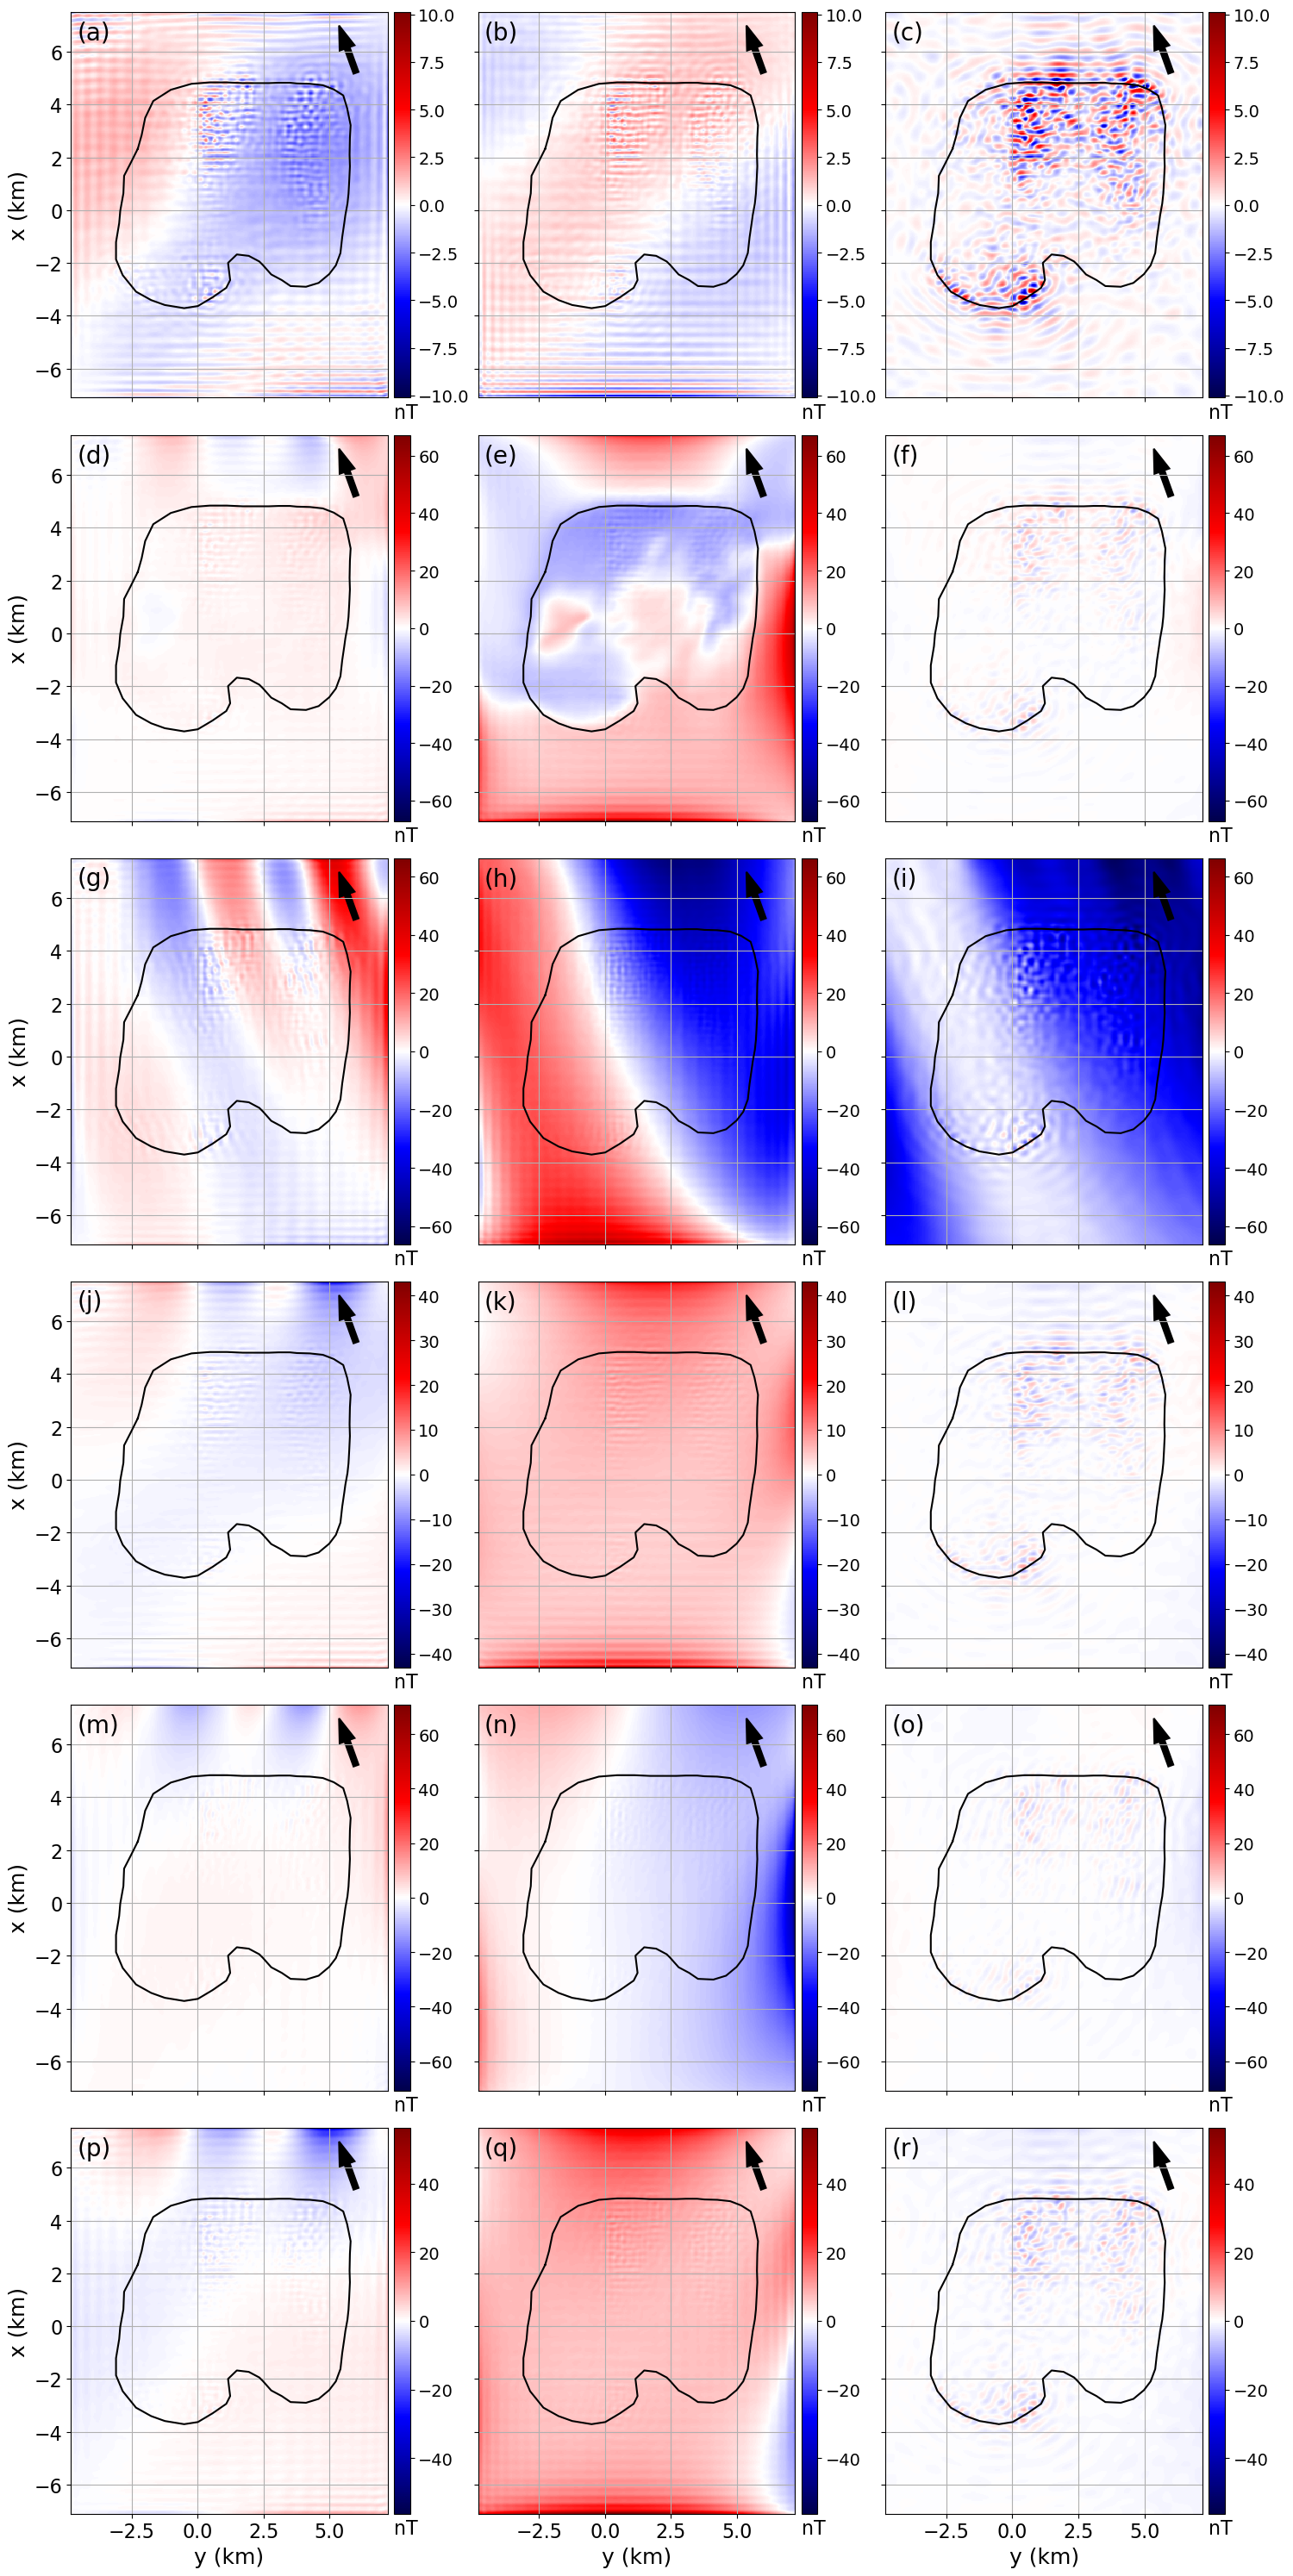

In [31]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,30)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             jkl
             mno
             pqr
             ''',
    sharex=True, sharey=True
)

labels = [
    ['(a)', '(b)', '(c)'], 
    ['(d)', '(e)', '(f)'], 
    ['(g)', '(h)', '(i)'], 
    ['(j)', '(k)', '(l)'], 
    ['(m)', '(n)', '(o)'],
    ['(p)', '(q)', '(r)']
]

mosaic_elements = [
    ['a', 'b', 'c'], 
    ['d', 'e', 'f'], 
    ['g', 'h', 'i'], 
    ['j', 'k', 'l'], 
    ['m', 'n', 'o'],
    ['p', 'q', 'r']
]

for (mosaic_row, labels_row, field) in zip(
    mosaic_elements, 
    labels,
    ['atfa', 'b', 'rtp', 'bx', 'by', 'bz']
):
    data_list = [
        Neumanns_predicted_fields[field] - simulated_fields[field],
        dipole_predicted_fields[field] - simulated_fields[field],
        generic_predicted_fields[field] - simulated_fields[field]
    ]
    bound = np.max(np.abs(data_list))
    
    for mosaic_element, data, label in zip(mosaic_row, data_list, labels_row):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                ordering='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        ax.arrow(
            x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
            width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, color='black'
        )

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a','d','g', 'j', 'm', 'p']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['p','q', 'r']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)

plt.savefig(figures+'6_data_fits.png', dpi=300)

plt.show()

### Plot the equivalent layers

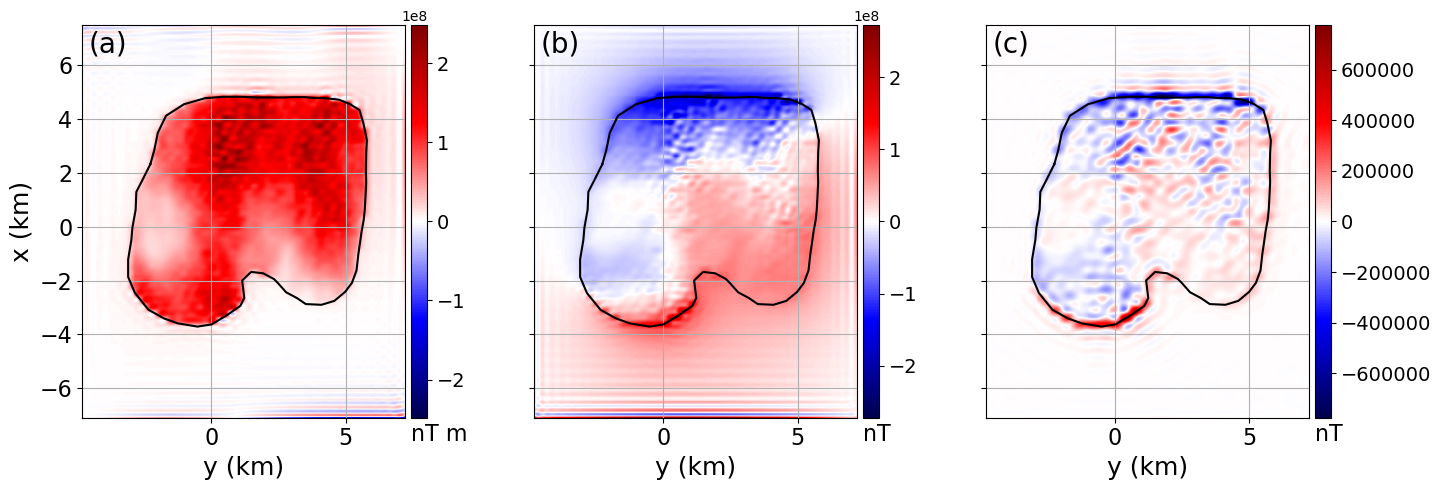

In [32]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,5)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)']

mosaic_elements = ['a', 'b', 'c']

units = ['nT m'] + ['nT'] + ['nT']


ranges = [
    np.max(np.abs(Neumanns_layer)),
    np.max(np.abs(dipole_layer)),
    np.max(np.abs(generic_layer))
]

for (element, layer, label, ranges_layer, unit) in zip(
    mosaic_elements, 
    [Neumanns_layer, dipole_layer, generic_layer], 
    labels,
    ranges,
    units,
):
    ax = mosaic[element]
    ax.axis('scaled')
    im = ax.pcolormesh(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=layer,
            ordering='xy',
            shape=coordinates_grid['shape']
        ),
        cmap='seismic', vmin=-ranges_layer, vmax=ranges_layer
    )
    ax_divider = make_axes_locatable(ax)
    cax = ax_divider.append_axes("right", size="5%", pad="2%")
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=14)
    cb.ax.set_xlabel(unit, fontsize=16, loc='left')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
    # ax.arrow(x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
    #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='black') 

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['a','b','c']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)  
    
plt.savefig(figures+'6_layers.png', dpi=300)

plt.show()